In [1]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/hasninourasma/labels-csv/frame_predictions.csv
/kaggle/input/datasets/hasninourasma/embeddings-cnn/file.npz


In [2]:
import os
import numpy as np
import pandas as pd

In [3]:
data = np.load("/kaggle/input/datasets/hasninourasma/embeddings-cnn/file.npz")

In [4]:
print(data.files)

for key in data.files:
    print(key, data[key].shape)


['embeddings', 'sequence', 'frame', 'split']
embeddings (11544, 64)
sequence (11544,)
frame (11544,)
split (11544,)


In [6]:
embeddings = data["embeddings"]
sequence = data["sequence"]
frame = data["frame"]
split = data["split"]

print(embeddings.shape)
print(sequence.shape)
print(frame.shape)
print(split.shape)

(11544, 64)
(11544,)
(11544,)
(11544,)


In [7]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/hasninourasma/labels-csv/frame_predictions.csv
/kaggle/input/datasets/hasninourasma/embeddings-cnn/file.npz


In [8]:
import pandas as pd

labels_df = pd.read_csv("/kaggle/input/datasets/hasninourasma/labels-csv/frame_predictions.csv")

print(len(labels_df))
print(embeddings.shape)

11544
(11544, 64)


In [9]:

from sklearn.preprocessing import LabelEncoder

# Create a dataframe for CNN embeddings
embedding_df = pd.DataFrame({
    "sequence": sequence.astype(str),
    "frame": frame,
    "split": split.astype(str),
    "embedding": list(embeddings)
})

# Copy labels dataframe
labels_df = labels_df.copy()

labels_df["sequence"] = labels_df["sequence"].astype(str)
labels_df["split"] = labels_df["split"].astype(str)

# Match embeddings with their corresponding labels
df = embedding_df.merge(
    labels_df[["sequence", "frame", "split", "true_class"]],
    on=["sequence", "frame", "split"],
    how="inner",
    validate="one_to_one"
)

# Sort frames
df = df.sort_values(["sequence", "frame"])

print("Matched rows:", len(df))
print("Classes:", df["true_class"].unique())
print("Splits:", df["split"].unique())

# Encode labels
le = LabelEncoder()
df["label"] = le.fit_transform(df["true_class"])

print("Label mapping:")

for i, name in enumerate(le.classes_):
    print(i, "=", name)


Matched rows: 11544
Classes: ['not_lying' 'falling' 'lying']
Splits: ['train' 'test' 'val']
Label mapping:
0 = falling
1 = lying
2 = not_lying


In [12]:

WINDOW_SIZE = 10
STRIDE = 1

X_data = {
    "train": [],
    "val": [],
    "test": []
}

y_data = {
    "train": [],
    "val": [],
    "test": []
}

for (seq_id, split_name), group in df.groupby(
    ["sequence", "split"], sort=False
):

    group = group.sort_values("frame")

    X = np.stack(group["embedding"].values)
    y = group["label"].to_numpy()
    frame_numbers = group["frame"].to_numpy()

    for i in range(
        0,
        len(group) - WINDOW_SIZE + 1,
        STRIDE
    ):

        # Check consecutive frames
        if not np.all(
            np.diff(frame_numbers[i:i+WINDOW_SIZE]) == 1
        ):
            continue

        # 10 frames, 64 features each
        X_data[split_name].append(
            X[i:i+WINDOW_SIZE]
        )

        # Label of the last frame
        y_data[split_name].append(
            y[i+WINDOW_SIZE-1]
        )


In [13]:

X_train_rnn = np.array(X_data["train"], dtype=np.float32)
X_val_rnn = np.array(X_data["val"], dtype=np.float32)
X_test_rnn = np.array(X_data["test"], dtype=np.float32)

y_train = np.array(y_data["train"])
y_val = np.array(y_data["val"])
y_test = np.array(y_data["test"])

print("Training:", X_train_rnn.shape, y_train.shape)
print("Validation:", X_val_rnn.shape, y_val.shape)
print("Testing:", X_test_rnn.shape, y_test.shape)


Training: (7503, 10, 64) (7503,)
Validation: (1755, 10, 64) (1755,)
Testing: (1648, 10, 64) (1648,)


In [14]:
print("Input shape:", X_train_rnn.shape)

print("Training labels:", np.unique(y_train, return_counts=True))
print("Validation labels:", np.unique(y_val, return_counts=True))
print("Testing labels:", np.unique(y_test, return_counts=True))

Input shape: (7503, 10, 64)
Training labels: (array([0, 1, 2]), array([1208, 1575, 4720]))
Validation labels: (array([0, 1, 2]), array([ 204,  306, 1245]))
Testing labels: (array([0, 1, 2]), array([301, 492, 855]))


In [15]:
labels_df.groupby("sequence").size().head()

sequence
adl-01    144
adl-02    150
adl-03    180
adl-04    150
adl-05    180
dtype: int64

In [16]:
print(labels_df["true_class"].value_counts())

true_class
not_lying    7452
lying        2373
falling      1719
Name: count, dtype: int64


In [17]:
labels_df.groupby("sequence")["true_class"].nunique().value_counts()


true_class
3    46
1    24
Name: count, dtype: int64

In [22]:

print("Train:", X_train_rnn.shape)
print("Validation:", X_val_rnn.shape)
print("Test:", X_test_rnn.shape)

Train: (7503, 10, 64)
Validation: (1755, 10, 64)
Test: (1648, 10, 64)


In [20]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

lstm_model = Sequential([
    Input(shape=(10, 64)),
    LSTM(64),
    Dropout(0.3),
    Dense(len(le.classes_), activation="softmax")
])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,219 (129.76 KB)

 Trainable params: 33,219 (129.76 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
history = lstm_model.fit(
    X_train_rnn,
    y_train,
    validation_data=(X_val_rnn, y_val),
    epochs=20,
    batch_size=64
)

Epoch 1/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.8673 - loss: 0.3386 - val_accuracy: 0.9140 - val_loss: 0.2882
Epoch 2/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8892 - loss: 0.2710 - val_accuracy: 0.9157 - val_loss: 0.2774
Epoch 3/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8934 - loss: 0.2616 - val_accuracy: 0.9202 - val_loss: 0.2697
Epoch 4/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8927 - loss: 0.2589 - val_accuracy: 0.9140 - val_loss: 0.2824
Epoch 5/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9016 - loss: 0.2504 - val_accuracy: 0.8912 - val_loss: 0.3004
Epoch 6/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9058 - loss: 0.2407 - val_accuracy: 0.9197 - val_loss: 0.2699
Epoch 7/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9059 - loss: 0.2377 - val_accuracy: 0.9231 - val_loss: 0.2771
Epoch 8/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9118 - loss: 0.2310 - val_accuracy: 0

In [23]:
test_loss, test_acc = lstm_model.evaluate(
    X_test_rnn,
    y_test
)

print("Test Accuracy:", test_acc)

52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8726 - loss: 0.4817
Test Accuracy: 0.8725728392601013


In [24]:
y_pred = np.argmax(
    lstm_model.predict(X_test_rnn),
    axis=1
)

52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


In [25]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(le.classes_)),
        target_names=le.classes_,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     falling       0.75      0.70      0.72       301
       lying       0.96      0.87      0.91       492
   not_lying       0.87      0.93      0.90       855

    accuracy                           0.87      1648
   macro avg       0.86      0.84      0.85      1648
weighted avg       0.87      0.87      0.87      1648



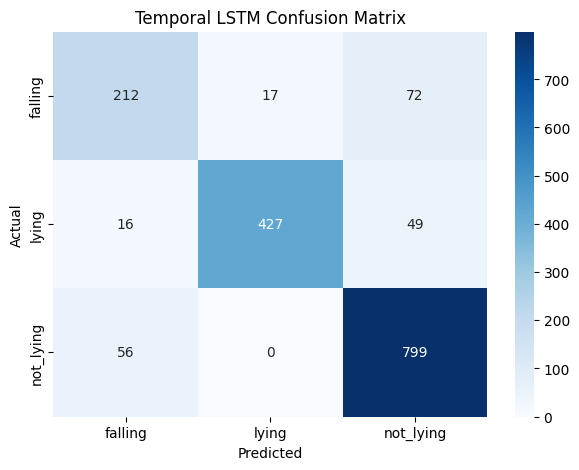

In [26]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(le.classes_))
)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Temporal LSTM Confusion Matrix")
plt.show()

In [27]:
lstm_model.save("rnn_temporal_model.keras")

In [28]:
from IPython.display import FileLink

FileLink("rnn_temporal_model.keras")

/kaggle/working/rnn_temporal_model.keras